Find god taksonomi - https://www.census.gov/naics/?input=71&chart=2017 ? foursquare?



In [1]:
from datetime import datetime, timedelta, date
import math
from pathlib import Path

import duckdb
import contextily as cx
import geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import networkx as nx
import numpy as np
import orjson
import pandas as pd
import polars as pl
import seaborn as sns
import shapely
import statsmodels.formula.api as smf
from tqdm import tqdm

from wpp import db
from wpp.segregation import data
from wpp.utils import project_root

In [22]:
# config
sns.set_theme(style="ticks")
pl.Config.set_engine_affinity("streaming")

root = project_root()
db_path = root / "wpp.duckdb"
con = db.connect(db_path)

In [3]:
query = """
    WITH v AS (
        SELECT ID_STORE, SUM(VISITOR_COUNTS) AS TOTAL_VISITORS
        FROM visits
        GROUP BY ID_STORE
    )
    SELECT p.*, v.TOTAL_VISITORS AS VISITORS
    FROM pois p
    JOIN v ON p.ID_STORE = v.ID_STORE
    WHERE CBSAFP = '35620'
"""
pois_dim = con.sql(query).pl().with_columns(
    pl.len().over("TOP_CATEGORY").alias("NUM_CATEGORY_POIS")
)
top_categories = set(pois_dim.group_by("TOP_CATEGORY").len().top_k(6, by="len")["TOP_CATEGORY"])
pois_dim = pois_dim.with_columns(
    pl.when(pl.col("TOP_CATEGORY").is_in(top_categories))
        .then(pl.col("TOP_CATEGORY"))
        .otherwise(pl.lit("Other"))
        .alias("TOP_CATEGORY_K")
)
pois_dim.head()

ID_STORE,POI_GEOID,CBSAFP,PERSISTENT_ID,BRAND,LOCATION_NAME,STREET_ADDRESS,CITY,REGION,ISO_COUNTRY_CODE,NAICS_CODE,TOP_CATEGORY,SUB_CATEGORY,OPEN_DATE,CLOSE_DATE,LONGITUDE,LATITUDE,GEOM,CELL_ID,VISITORS,NUM_CATEGORY_POIS,TOP_CATEGORY_K
str,str,str,str,str,str,str,str,str,str,str,str,str,date,date,f64,f64,ext[geoarrow.wkb],i64,"decimal[38,0]",u32,str
"""12965049""","""340170200004""","""35620""","""A1_RESTAURANT-A""","""Restaurants""","""La Mia Cucina""","""161 Front St""","""Secaucus""","""NJ""","""US""","""722511""","""Restaurants and Other Eating P…","""Full-Service Restaurants """,1970-01-01,2038-01-01,-74.059484,40.790928,"b""\x01\x01\x00\x00\x00\xa8\xa8\xfa\x95\xce\x83R\xc0\xcf\xbe\xf2\x20=eD@""",308918,5589,58126,"""Restaurants and Other Eating P…"
"""12967283""","""360610072006""","""35620""","""A1_RESTAURANT-A""","""Restaurants""","""Le Parisien""","""163 E 33rd St""","""New York""","""NY""","""US""","""722511""","""Restaurants and Other Eating P…","""Full-Service Restaurants """,1970-01-01,2038-01-01,-73.97913,40.745482,"b""\x01\x01\x00\x00\x00\x08\x01\xf9\x12\xaa~R\xc0\xdb\xe0D\xf4k_D@""",310325,12093,58126,"""Restaurants and Other Eating P…"
"""12967314""","""360610087004""","""35620""","""A1_RESTAURANT-A""","""Restaurants""","""Le Zie""","""172 7th Ave""","""New York""","""NY""","""US""","""722511""","""Restaurants and Other Eating P…","""Full-Service Restaurants """,1970-01-01,2038-01-01,-73.997091,40.74255,"b""\x01\x01\x00\x00\x00\xa7\xe7\xddX\xd0\x7fR\xc0\x89\xd2\xde\xe0\x0b_D@""",310324,10806,58126,"""Restaurants and Other Eating P…"
"""12969685""","""340130069002""","""35620""","""A1_RESTAURANT-A""","""Restaurants""","""Los Cazahuates Restaurant""","""118 Pacific St""","""Newark""","""NJ""","""US""","""722511""","""Restaurants and Other Eating P…","""Full-Service Restaurants """,1970-01-01,2038-01-01,-74.167354,40.723813,"b""\x01\x01\x00\x00\x00\xc1Wt\xeb\xb5\x8aR\xc0\x9fs\xb7\xeb\xa5\D@""",311725,10181,58126,"""Restaurants and Other Eating P…"
"""12974444""","""340312463002""","""35620""","""A1_RESTAURANT-A""","""Restaurants""","""Master Wok""","""1400 Willowbrook Mall""","""Wayne""","""NJ""","""US""","""722511""","""Restaurants and Other Eating P…","""Full-Service Restaurants """,1970-01-01,2038-01-01,-74.259844,40.88843,"b""\x01\x01\x00\x00\x00\xe9b\xd3J\xa1\x90R\xc0l""3\x17\xb8qD@""",306103,129979,58126,"""Restaurants and Other Eating P…"


We can use different definitions. For now, we use an adapted POI segregation from [Moro et al.](https://www.nature.com/articles/s41467-021-24899-8)

> To measure the income segregation of each place $\alpha$ in the city, we compute the proportion of total time spent at that place $\alpha$ by each income quartile $q$, $\tau _{q, \alpha}$, defining separate quartiles for each city. We define full integration of a place as $\tau _{q, \alpha} = \frac{1}{4}$ for each $q$, that is, the total time spent at venue $\alpha$ is split evenly across our four income quartiles. We then define the income segregation for each place $\alpha$, $S_\alpha$, as any deviation from our idealized measure of integration:
> $$S_{\alpha} = \frac{2}{3}\sum_{q=1}^{4}\left|\tau_{q\alpha} - \frac{1}{4}\right|$$

This definition generalizes to any number of groups as

$$
S_{\alpha}^{\{n\}} = \frac{n}{2n - 2}\sum_{q=1}^{n}\left|\tau_{q\alpha} - \frac{1}{n}\right|
$$

In [4]:
query = """
    WITH bg AS (
        SELECT
            GEOID, CBSAFP, MEDIAN_HH_INCOME,
            NTILE(4) OVER (PARTITION BY CBSAFP ORDER BY MEDIAN_HH_INCOME ASC) AS INCOME_GROUP
        FROM block_groups_cbsa
        WHERE CBSAFP = '35620'
          AND MEDIAN_HH_INCOME IS NOT NULL
    )
    SELECT v.ID_STORE, INCOME_GROUP, SUM(VISITOR_COUNTS) AS TOTAL_VISITORS
    FROM block_group_visits v
    JOIN bg ON v.HOME_GEOID = bg.GEOID
    GROUP BY v.ID_STORE, INCOME_GROUP
"""
poi_group_visits = con.sql(query).pl()
poi_visits = (
    poi_group_visits
        .sort("INCOME_GROUP")
        .pivot("INCOME_GROUP", index="ID_STORE", column_naming="combine")
        .fill_null(0)
        .with_columns(
            pl.sum_horizontal(pl.selectors.starts_with("TOTAL_VISITORS_")).alias("TOTAL_VISITORS")
        )
        .with_columns(
            (
                pl.selectors.starts_with("TOTAL_VISITORS_").cast(pl.Float64)
                / pl.col("TOTAL_VISITORS").replace({0: None})
            ).name.replace("TOTAL_VISITORS_", "TAU_")
        )
        .with_columns(
            (
                (2 / 3) * pl.sum_horizontal(
                    (pl.selectors.starts_with("TAU_") - (1/4)).abs()
                )
            ).alias("SEGREGATION")
        )
        .filter(pl.col("TOTAL_VISITORS") > 0)
)
poi_visits.head()

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

ID_STORE,TOTAL_VISITORS_1,TOTAL_VISITORS_2,TOTAL_VISITORS_3,TOTAL_VISITORS_4,TOTAL_VISITORS,TAU_1,TAU_2,TAU_3,TAU_4,SEGREGATION
str,"decimal[38,0]","decimal[38,0]","decimal[38,0]","decimal[38,0]","decimal[38,0]",f64,f64,f64,f64,f64
"""7565311""",271139,335327,367885,226121,1200472,0.22586,0.279329,0.30645,0.18836,0.114373
"""9554625""",110648,82503,72502,13354,279007,0.396578,0.295702,0.259857,0.047863,0.269517
"""10003681""",4338,22851,10403,6079,43671,0.099334,0.523253,0.238213,0.1392,0.364338
"""13630799""",28201,53594,17912,4937,104644,0.269495,0.512155,0.171171,0.047179,0.375534
"""8265919""",6758,21415,9929,3981,42083,0.160587,0.508875,0.235939,0.094599,0.345167


In [5]:
pois = pois_dim.join(poi_visits, on="ID_STORE")

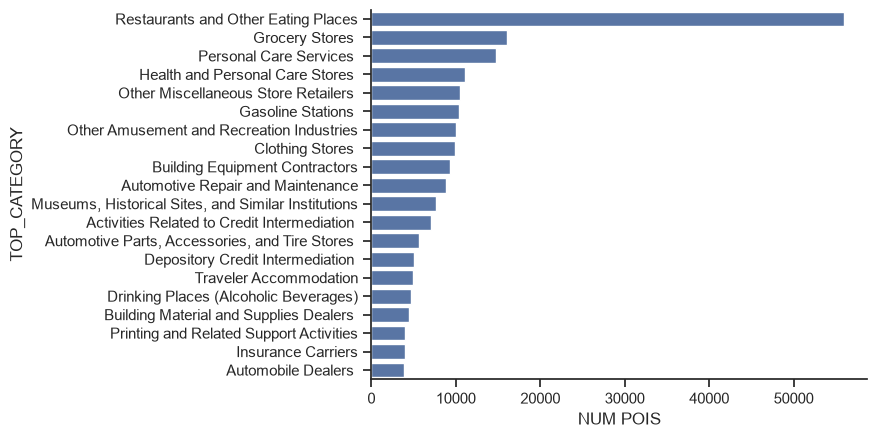

In [6]:
ax = sns.barplot(
    pois.group_by("TOP_CATEGORY").len().sort("len", descending=True).top_k(20, by="len").to_pandas(),
    y="TOP_CATEGORY",
    x="len"
)
ax.set_xlabel("NUM POIS")
sns.despine()

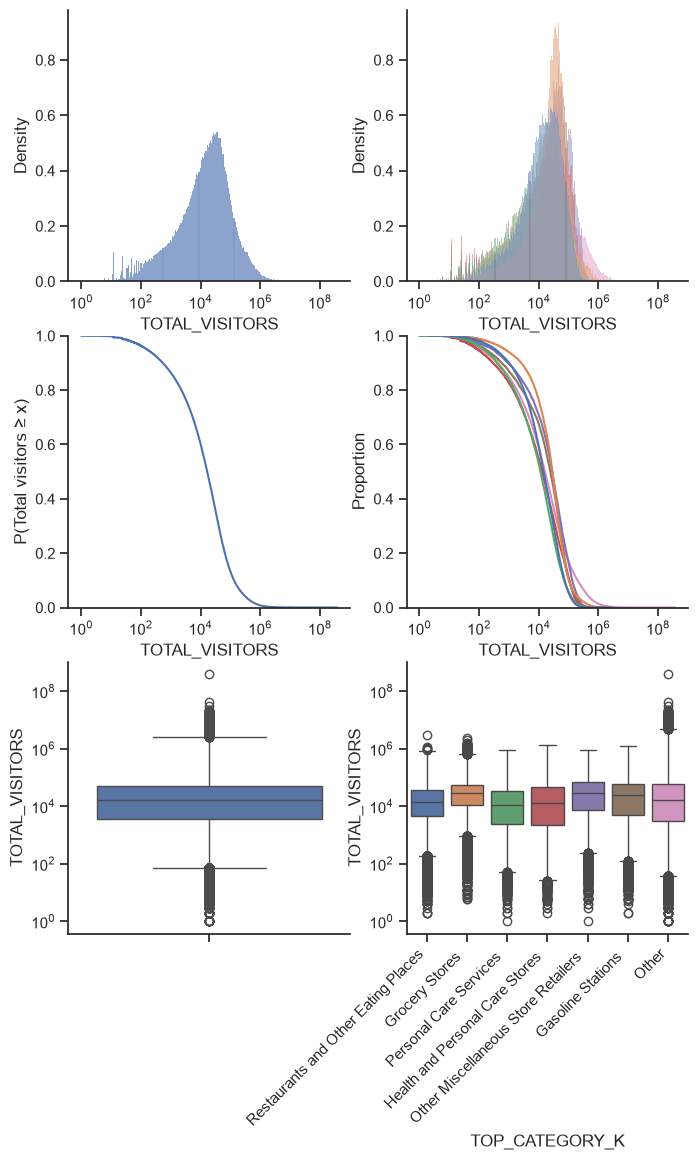

In [7]:
fig, axes = plt.subplots(3, 2, figsize=(8, 12))
pois_pd = pois.with_columns(
    pl.col("TOTAL_VISITORS").cast(pl.Float64),
    pl.col("SEGREGATION").cast(pl.Float64),  # in case this is Decimal too
).sort("NUM_CATEGORY_POIS", descending=True).to_pandas()
sns.histplot(
    pois_pd,
    x="TOTAL_VISITORS",
    stat="density",
    log_scale=True,
    ax=axes[0,0],
)
sns.histplot(
    pois_pd,
    x="TOTAL_VISITORS",
    hue="TOP_CATEGORY_K",
    common_bins=True,
    common_norm=False,
    stat="density",
    log_scale=True,
    ax=axes[0,1],
    legend=False
)
axes[0,0].sharex(axes[0,1])
axes[0,0].sharey(axes[0,1])

sns.ecdfplot(
    data=pois_pd,
    x="TOTAL_VISITORS",
    complementary=True,
    log_scale=True,
    ax=axes[1, 0],
)
sns.ecdfplot(
    data=pois_pd,
    x="TOTAL_VISITORS",
    hue="TOP_CATEGORY_K",
    complementary=True,
    log_scale=True,
    ax=axes[1, 1],
    legend=False,
)
axes[1,0].set_ylabel("P(Total visitors ≥ x)")
axes[1,0].sharex(axes[1,1])
axes[1,0].sharey(axes[1,1])

sns.boxplot(
    pois_pd,
    y="TOTAL_VISITORS",
    log_scale=True,
    ax=axes[2,0],
    legend=False
)

sns.boxplot(
    pois_pd,
    x="TOP_CATEGORY_K",
    y="TOTAL_VISITORS",
    log_scale=True,
    ax=axes[2,1],
    hue="TOP_CATEGORY_K",
    legend=False
)
axes[2,0].sharey(axes[2,1])
axes[2,1].tick_params("x", rotation=45, rotation_mode="xtick")

sns.despine()

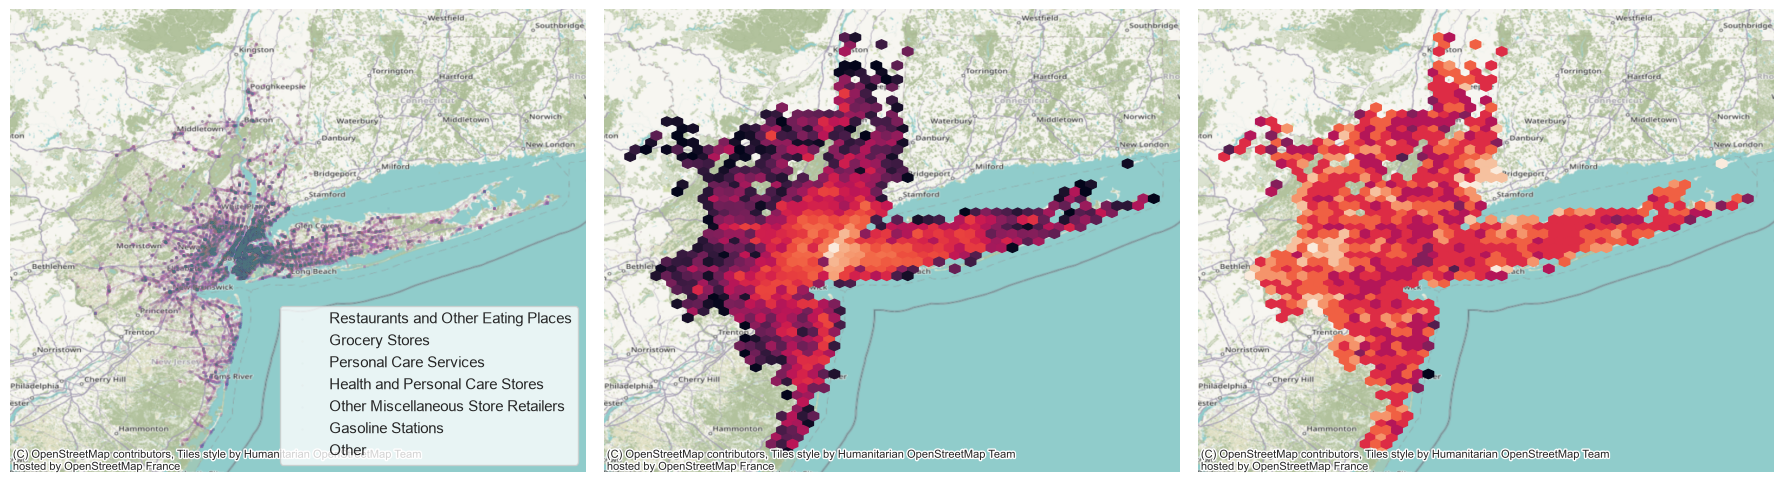

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(18,5), sharex=True, sharey=True)

for i, ((label,), g) in enumerate(pois.sort("NUM_CATEGORY_POIS", descending=True).group_by("TOP_CATEGORY_K", maintain_order=True)):
    axes[0].scatter(g["LONGITUDE"], g["LATITUDE"], s=.1, alpha=.05, label=label, zorder=10-i)
axes[0].legend()
    
axes[1].hexbin(pois["LONGITUDE"], pois["LATITUDE"], mincnt=5, bins="log", gridsize=(50,30))
axes[2].hexbin(pois["LONGITUDE"], pois["LATITUDE"], pois["SEGREGATION"], mincnt=5, bins=10, gridsize=(50,30))

for ax in axes:
    cx.add_basemap(ax, zoom='auto', crs='EPSG:4326')
    ax.set_axis_off()
fig.tight_layout()

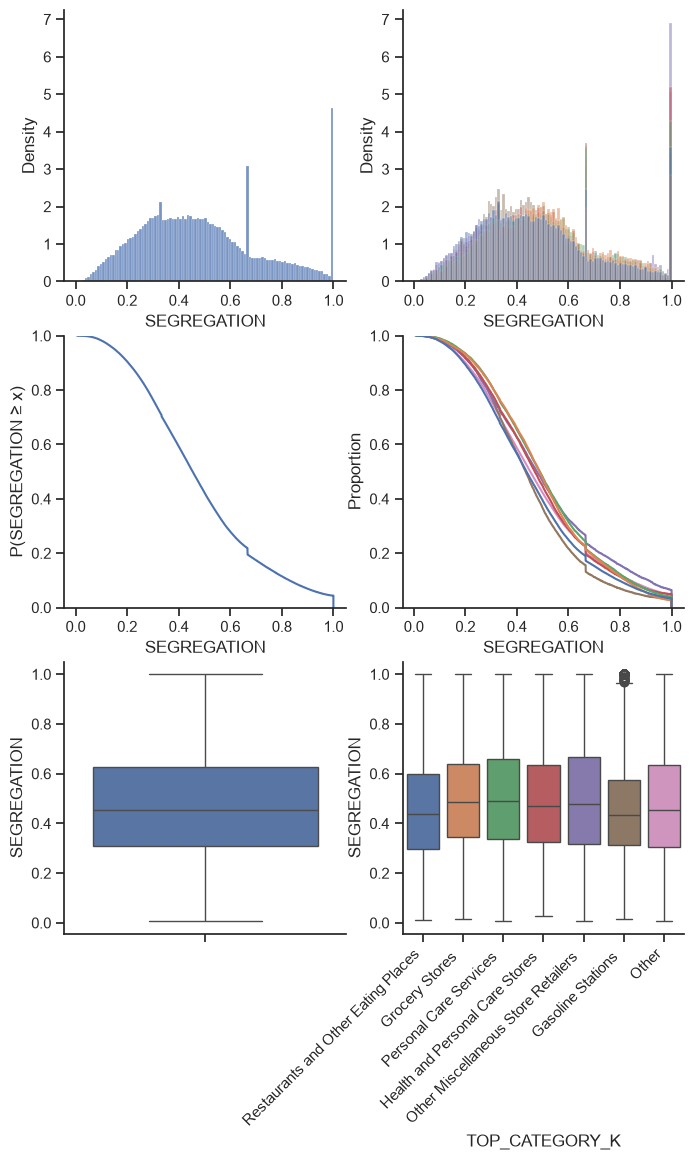

In [9]:
fig, axes = plt.subplots(3, 2, figsize=(8, 12))
pois_pd = pois.with_columns(
    pl.col("TOTAL_VISITORS").cast(pl.Float64),
    pl.col("SEGREGATION").cast(pl.Float64),  # in case this is Decimal too
).sort("NUM_CATEGORY_POIS", descending=True).to_pandas()
sns.histplot(
    pois_pd,
    x="SEGREGATION",
    stat="density",
    ax=axes[0,0],
)
sns.histplot(
    pois_pd,
    x="SEGREGATION",
    hue="TOP_CATEGORY_K",
    common_bins=True,
    common_norm=False,
    stat="density",
    ax=axes[0,1],
    legend=False
)
axes[0,0].sharex(axes[0,1])
axes[0,0].sharey(axes[0,1])

sns.ecdfplot(
    data=pois_pd,
    x="SEGREGATION",
    complementary=True,
    ax=axes[1, 0],
)
sns.ecdfplot(
    data=pois_pd,
    x="SEGREGATION",
    hue="TOP_CATEGORY_K",
    complementary=True,
    ax=axes[1, 1],
    legend=False,
)
axes[1,0].set_ylabel("P(SEGREGATION ≥ x)")
axes[1,0].sharex(axes[1,1])
axes[1,0].sharey(axes[1,1])

sns.boxplot(
    pois_pd,
    y="SEGREGATION",
    ax=axes[2,0],
    legend=False
)

sns.boxplot(
    pois_pd,
    x="TOP_CATEGORY_K",
    y="SEGREGATION",
    ax=axes[2,1],
    hue="TOP_CATEGORY_K",
    legend=False
)
axes[2,0].sharey(axes[2,1])
axes[2,1].tick_params("x", rotation=45, rotation_mode="xtick")

sns.despine()

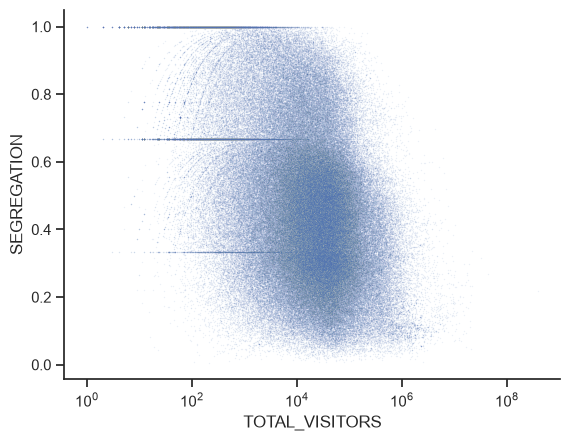

In [10]:
ax = sns.scatterplot(
    pois.to_pandas(),
    x="TOTAL_VISITORS",
    y="SEGREGATION",
    alpha=.1,
    s=1
)
ax.set_xscale("log")
sns.despine()

In [11]:
categories = pois.group_by("TOP_CATEGORY").agg(
    pl.len().alias("NUM_POIS"),
    pl.col("SEGREGATION").mean(),
    ((pl.col("SEGREGATION") * pl.col("TOTAL_VISITORS")).sum() / pl.col("TOTAL_VISITORS").sum()).alias("W_SEGREGATION"),
    pl.col("TOTAL_VISITORS").sum(),
    pl.col("TOTAL_VISITORS").mean().alias("AVG_VISITORS")
)
top_categories = pl.concat([
    categories.filter(pl.col("NUM_POIS") >= 100).bottom_k(5, by="W_SEGREGATION"),
    categories.filter(pl.col("NUM_POIS") >= 100).top_k(5, by="W_SEGREGATION"),
])

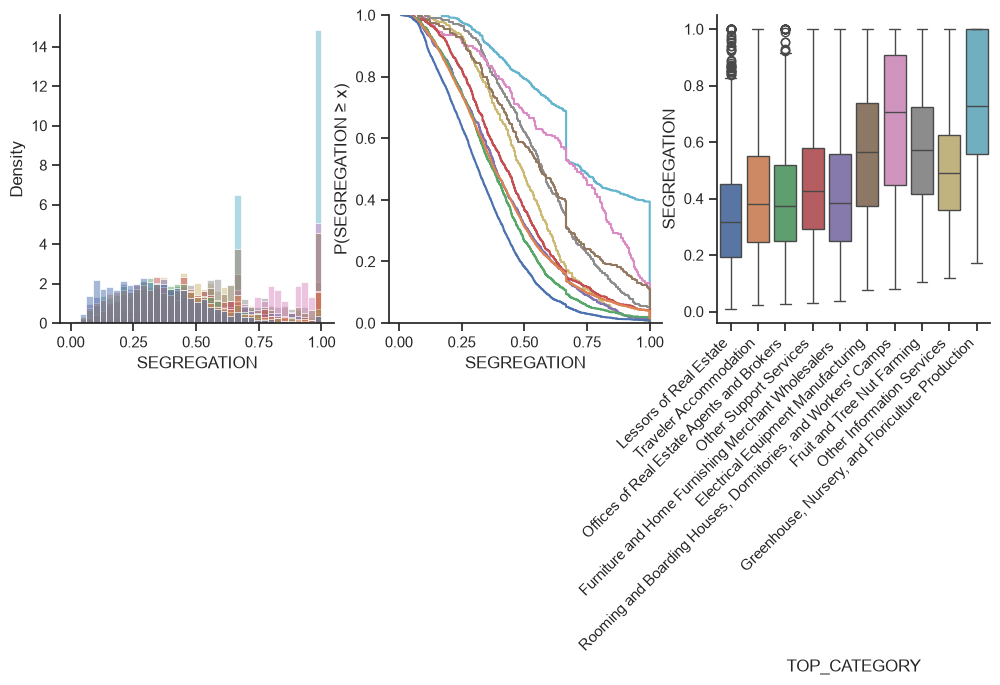

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(12, 4))

category_set = set(top_categories["TOP_CATEGORY"])
pois_pd = pois.filter(pl.col("TOP_CATEGORY").is_in(category_set)).with_columns(
    pl.col("TOTAL_VISITORS").cast(pl.Float64),
    pl.col("SEGREGATION").cast(pl.Float64),
).sort("SEGREGATION").to_pandas()

sns.histplot(
    pois_pd,
    x="SEGREGATION",
    hue="TOP_CATEGORY",
    common_bins=True,
    common_norm=False,
    stat="density",
    ax=axes[0],
    legend=False
)

sns.ecdfplot(
    data=pois_pd,
    x="SEGREGATION",
    hue="TOP_CATEGORY",
    complementary=True,
    ax=axes[1],
    legend=False,
)
axes[1].set_ylabel("P(SEGREGATION ≥ x)")

sns.boxplot(
    pois_pd,
    x="TOP_CATEGORY",
    y="SEGREGATION",
    ax=axes[2],
    hue="TOP_CATEGORY",
    legend=False
)
axes[2].tick_params("x", rotation=45, rotation_mode="xtick")

sns.despine()

## Data is messed up exploration

In [13]:
pois.filter(
    pl.col("TOTAL_VISITORS") > 10_000,
    pl.col("SEGREGATION") == 1
)

ID_STORE,POI_GEOID,CBSAFP,PERSISTENT_ID,BRAND,LOCATION_NAME,STREET_ADDRESS,CITY,REGION,ISO_COUNTRY_CODE,NAICS_CODE,TOP_CATEGORY,SUB_CATEGORY,OPEN_DATE,CLOSE_DATE,LONGITUDE,LATITUDE,GEOM,CELL_ID,VISITORS,NUM_CATEGORY_POIS,TOP_CATEGORY_K,TOTAL_VISITORS_1,TOTAL_VISITORS_2,TOTAL_VISITORS_3,TOTAL_VISITORS_4,TOTAL_VISITORS,TAU_1,TAU_2,TAU_3,TAU_4,SEGREGATION
str,str,str,str,str,str,str,str,str,str,str,str,str,date,date,f64,f64,ext[geoarrow.wkb],i64,"decimal[38,0]",u32,str,"decimal[38,0]","decimal[38,0]","decimal[38,0]","decimal[38,0]","decimal[38,0]",f64,f64,f64,f64,f64
"""8348244""","""360811571014""","""35620""","""A1_NAICS-446130""","""Optical Goods Stores""","""Optical Goods Stores""","""8050 252Nd St""","""Bellerose""","""NY""","""US""","""446130""","""Health and Personal Care Store…","""Optical Goods Stores """,1970-01-01,2038-01-01,-73.718224,40.742249,"b""\x01\x01\x00\x00\x00\xc9M\x1e`\xf7mR\xc0\xa6\x80\xb4\xff\x01_D@""",310331,30168,12034,"""Health and Personal Care Store…",0,29297,0,0,29297,0.0,1.0,0.0,0.0,1.0
"""13460815""","""340258087011""","""35620""","""A1_MALL-A""","""Mall""","""Circle Factory Outlet Center""","""1407 Atlantic Ave""","""Manasquan""","""NJ""","""US""","""531120""","""Lessors of Real Estate""","""Lessors of Nonresidential Buil…",1970-01-01,2038-01-01,-74.068204,40.131556,"b""\x01\x01\x00\x00\x005]Ot]\x84R\xc0\xda\xcb\xb6\xd3\xd6\x10D@""",331397,321881,3390,"""Other""",0,0,0,63829,63829,0.0,0.0,0.0,1.0,1.0
"""8274193""","""340230082131""","""35620""","""A1_NAICS-453998""","""All Other Miscellaneous Store …","""Dhesis Fuel And Mart LLC""","""7 Helen Ct""","""Monroe Township""","""NJ""","""US""","""453998""","""Other Miscellaneous Store Reta…","""All Other Miscellaneous Store …",1970-01-01,2038-01-01,-74.408882,40.320648,"b""\x01\x01\x00\x00\x00\xde\xda\xd3\x1f+\x9aR\xc0\xb9B\x0e\x00\x0b)D@""",324364,20644,11260,"""Other Miscellaneous Store Reta…",0,0,0,12824,12824,0.0,0.0,0.0,1.0,1.0
"""8340620""","""360811113002""","""35620""","""A1_NAICS-453998""","""All Other Miscellaneous Store …","""Pyrosignal And Suppression, In…","""4032 216Th St""","""Bayside""","""NY""","""US""","""453998""","""Other Miscellaneous Store Reta…","""All Other Miscellaneous Store …",1970-01-01,2038-01-01,-73.766953,40.764599,"b""\x01\x01\x00\x00\x00xE\xf0\xbf\x15qR\xc0_\x07s`\xdeaD@""",310330,93191,11260,"""Other Miscellaneous Store Reta…",0,0,15361,0,15361,0.0,0.0,1.0,0.0,1.0
"""12413615""","""340258007022""","""35620""","""A1_NAICS-453998""","""All Other Miscellaneous Store …","""WAWA #8460""","""RT 35 & MONMOUTH ROAD""","""MIDDLETOWN""","""NJ""","""US""","""453998""","""Other Miscellaneous Store Reta…","""All Other Miscellaneous Store …",1970-01-01,2038-01-01,-74.11535,40.40757,"b""\x01\x01\x00\x00\x00\xfee\xf7\xe4a\x87R\xc0Uj\xf6@+4D@""",321561,66252,11260,"""Other Miscellaneous Store Reta…",0,0,30653,0,30653,0.0,0.0,1.0,0.0,1.0
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
"""8352928""","""360050151002""","""35620""","""A1_NAICS-722513""","""Limited-Service Restaurants""","""Limited-Service Restaurants""","""1378 Boston Rd""","""Bronx""","""NY""","""US""","""722513""","""Restaurants and Other Eating P…","""Limited-Service Restaurants """,1970-01-01,2038-01-01,-73.897987,40.832539,"b""\x01\x01\x00\x00\x00\x16\xce$\xa0xyR\xc0-\xd4\xf5\x9f\x90jD@""",307516,14228,58126,"""Restaurants and Other Eating P…",10043,0,0,0,10043,1.0,0.0,0.0,0.0,1.0
"""13131749""","""360050389005""","""35620""","""A1_GROCERY-A""","""Grocery Stores""","""Scalinada Grocery Store""","""667 E 187th St""","""Bronx""","""NY""","""US""","""445110""","""Grocery Stores ""","""Supermarkets and Other Grocery…",1970-01-01,2038-01-01,-73.885536,40.854765,"b""\x01\x01\x00\x00\x00\x9c\xfc\x16\x9d\xacxR\xc0\xe2\x1f\xb6\xf4hmD@""",306112,13385,16519,"""Grocery Stores """,10266,0,0,0,10266,1.0,0.0,0.0,0.0,1.0
"""10310322""","""360593029003""","""35620""","""A1_NAICS-722514""","""Cafeterias, Grill Buffets, and…","""Cafeterias, Grill Buffets, and…","""27120 

In [14]:
con.sql("""
    SELECT *
    FROM block_group_visits
    WHERE ID_STORE = '8275101'
""").pl()

HOME_GEOID,ID_STORE,DATE_RANGE_START,DATE_RANGE_END,VISITOR_COUNTS
str,str,datetime[μs],datetime[μs],i32
"""340030242003""","""8275101""",2025-01-06 00:00:00,2025-01-12 00:00:00,627
"""340030242003""","""8275101""",2025-09-08 00:00:00,2025-09-14 00:00:00,126
"""340030242003""","""8275101""",2025-09-29 00:00:00,2025-10-05 00:00:00,102
"""340030242003""","""8275101""",2025-04-14 00:00:00,2025-04-20 00:00:00,691
"""340030242003""","""8275101""",2025-04-21 00:00:00,2025-04-27 00:00:00,701
…,…,…,…,…
"""340030242003""","""8275101""",2025-06-30 00:00:00,2025-07-06 00:00:00,94
"""340030242003""","""8275101""",2025-08-04 00:00:00,2025-08-10 00:00:00,116
"""340030242003""","""8275101""",2025-08-18 00:00:00,2025-08-24 00:00:00,115


In [15]:
df = con.sql("""
    SELECT
        * EXCLUDE (geom),
        ST_AsText(geom) AS wkt
    FROM block_groups
    WHERE CBSAFP = '35620'
""").df()

gbg = gpd.GeoDataFrame(
    df,
    geometry=gpd.GeoSeries.from_wkt(df["wkt"]),
    crs="EPSG:4269"
).drop(columns="wkt")

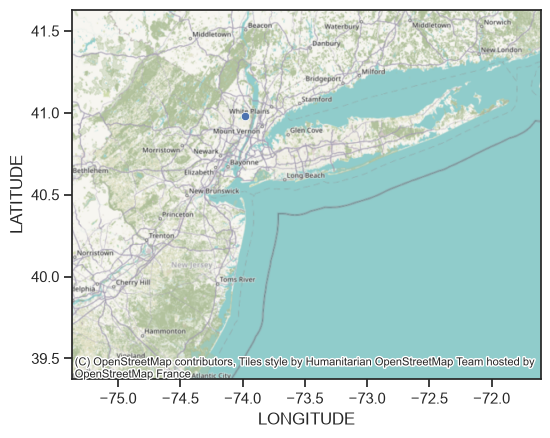

In [16]:
ax = gbg.boundary.plot(linewidth=.0, color="lightgrey")
sns.scatterplot(
    pois.filter(pl.col.ID_STORE == '8275101').to_pandas(),
    x="LONGITUDE",
    y="LATITUDE",
    ax=ax,
    zorder=10
)
cx.add_basemap(ax, crs="EPSG:4236")

In [17]:
pois.filter(pl.col.ID_STORE == "8275101")

ID_STORE,POI_GEOID,CBSAFP,PERSISTENT_ID,BRAND,LOCATION_NAME,STREET_ADDRESS,CITY,REGION,ISO_COUNTRY_CODE,NAICS_CODE,TOP_CATEGORY,SUB_CATEGORY,OPEN_DATE,CLOSE_DATE,LONGITUDE,LATITUDE,GEOM,CELL_ID,VISITORS,NUM_CATEGORY_POIS,TOP_CATEGORY_K,TOTAL_VISITORS_1,TOTAL_VISITORS_2,TOTAL_VISITORS_3,TOTAL_VISITORS_4,TOTAL_VISITORS,TAU_1,TAU_2,TAU_3,TAU_4,SEGREGATION
str,str,str,str,str,str,str,str,str,str,str,str,str,date,date,f64,f64,ext[geoarrow.wkb],i64,"decimal[38,0]",u32,str,"decimal[38,0]","decimal[38,0]","decimal[38,0]","decimal[38,0]","decimal[38,0]",f64,f64,f64,f64,f64
"""8275101""","""340030242003""","""35620""","""A1_NAICS-445110""","""Supermarkets and Other Grocery…","""Supermarkets and Other Grocery…","""207 Laroche Ave""","""Harrington Park""","""NJ""","""US""","""445110""","""Grocery Stores ""","""Supermarkets and Other Grocery…",1970-01-01,2038-01-01,-73.983841,40.982262,"b""\x01\x01\x00\x00\x00\xe7}\xd2?\xf7~R\xc0\x83\xceZ\xc0\xba}D@""",301894,18063,16519,"""Grocery Stores """,0,0,0,14859,14859,0.0,0.0,0.0,1.0,1.0


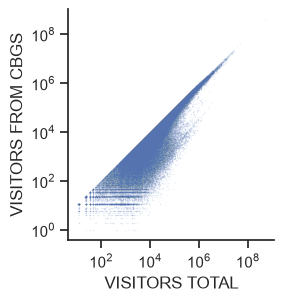

In [19]:
fig, ax = plt.subplots(figsize=(3,3))
sns.scatterplot(
    pois.to_pandas(),
    x="VISITORS",
    y="TOTAL_VISITORS",
    alpha=.1,
    s=1,
    ax=ax
)
vals = pois.to_pandas()[["VISITORS", "TOTAL_VISITORS"]]
lo = vals[vals > 0].min().min()
hi = vals.max().max()
lims = (10 ** np.floor(np.log10(lo)), 10 ** np.ceil(np.log10(hi)))
ticks = 10 ** np.arange(np.log10(lims[0]), np.log10(lims[1]) + 1)
ax.set(
    xlabel="VISITORS TOTAL",
    ylabel="VISITORS FROM CBGS",
    xticks=ticks,
    yticks=ticks,
    xscale="log",
    yscale="log",
)
ax.set_aspect('equal', adjustable='box')
sns.despine()

In [47]:
bg_dist = con.sql("""
    select v.ID_STORE, HOME_GEOID, SUM(VISITOR_COUNTS) AS VISITOR_COUNTS, COUNT(*) AS NUM_WEEKS
    from block_group_visits v
    join pois p on v.ID_STORE = p.ID_STORE
    where p.CBSAFP = '35620'
    group by v.ID_STORE, HOME_GEOID
""").pl()

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 5/5 [00:03<00:00,  1.46it/s]


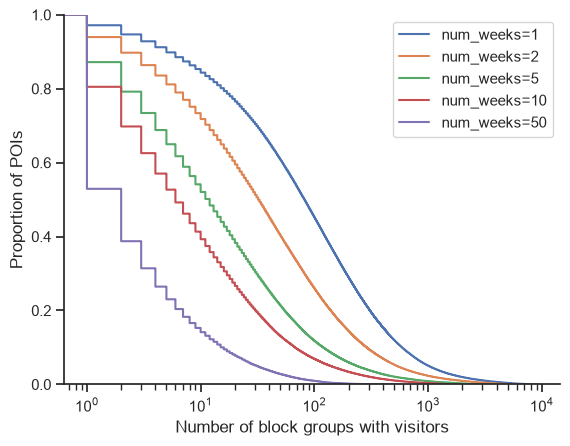

In [56]:
fig, ax = plt.subplots()
for t in tqdm([1, 2, 5, 10, 50]):
    d = bg_dist.filter(pl.col("NUM_WEEKS") >= t).group_by("ID_STORE").agg(pl.col("HOME_GEOID").n_unique().alias("NUM_BGS"))
    sns.ecdfplot(d["NUM_BGS"], complementary=True, label=f"num_weeks={t}")
ax.set_xscale("log")
ax.set_ylabel("Proportion of POIs")
ax.set_xlabel("Number of block groups with visitors")
ax.legend()
sns.despine()

100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 6/6 [00:03<00:00,  1.59it/s]


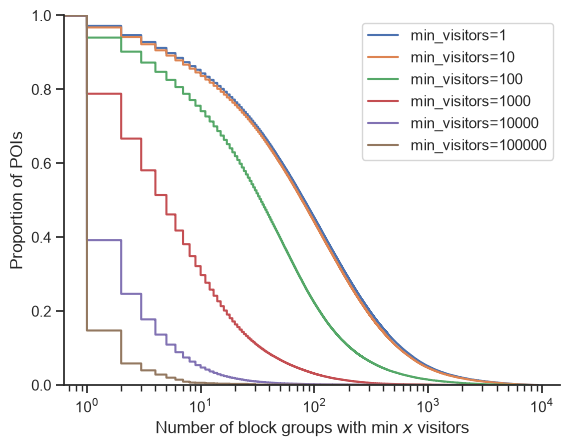

In [49]:
fig, ax = plt.subplots()
for t in tqdm([1, 10, 100, 1_000, 10_000, 100_000]):
    d = bg_dist.filter(pl.col("VISITOR_COUNTS") >= t).group_by("ID_STORE").agg(pl.col("HOME_GEOID").n_unique().alias("NUM_BGS"))
    sns.ecdfplot(d["NUM_BGS"], complementary=True, label=f"min_visitors={t}")
ax.set_xscale("log")
ax.set_ylabel("Proportion of POIs")
ax.set_xlabel("Number of block groups with min $x$ visitors")
ax.legend()
sns.despine()

In [ ]:
con.close()